# Lab 4: Pulse Shaping, Probability of Error, and Multilevel ASK

Lab 3 gave you a working transmit/receive chain: bits to symbols to a pulse train, over the
air, corrected for CFO and phase, demodulated, scored. Two things in that chain were left
mostly unexamined. First, `sps = 8` samples per symbol were shaped and matched-filtered by
simple repetition and averaging, without ever asking *why* that's the right receiver for that
pulse, or what it buys you. Second, "sweep the receiver gain" was a workable stand-in for
"sweep the SNR" -- close enough for a Bonus section, but not something you could honestly
overlay against $P_b = Q(\sqrt{2E_b/N_0})$.

This lab closes both gaps, then pushes the constellation idea further than binary.

**Part 1** formalizes pulse shaping and matched filtering as their own general operations (not
just "the `sps` trick"), then uses them to build an actual **probability-of-error-vs-SNR**
curve for BPSK -- estimating SNR itself from the same preamble you already rely on for sync,
rather than reading it off a gain knob.

**Part 2** leaves the SDR behind for a while: entirely in simulation, you'll build a
constellation that combines 4-ASK on the in-phase axis with 2-ASK on the quadrature axis -- an
8-point rectangular constellation carrying 3 bits/symbol, and a first real example of
*independent* amplitude modulation on the two axes. Once that's simulated and understood,
you'll come back to hardware and put the simpler piece of it -- 4-ASK by itself -- on the air.

**What carries over from Lab 3, unchanged:** the two Plutos, `fs`, the preamble-based frame
structure, single-frame BER (one sized frame, one measurement, no pooling), and dynamic RX
buffer sizing per scheme. If any of that sounds unfamiliar, it's worth a quick look back at
Lab 3 before starting here.

## Hardware Configuration

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc
import adi

In [2]:
fs = int(2.0e6)                # Sample rate: 2.0 MHz (same as Labs 2-3)
fc = int(763e6)                     # RF carrier (Hz) -- same band you've used in Labs 2-3,
                                  # e.g. somewhere in the ISM band around 915e6

# --- Frame / waveform parameters -------------------------------------
sps              = 8             # samples per symbol -- how many samples your rectangular
                                  # pulse (Task 2) holds each symbol for
preamble_len     = 2000          # samples in the constant-symbol preamble (sync, phase/amp
                                  # reference, AND -- new this lab -- the SNR probe of Task 6)
preamble_scale   = 1.5           # preamble amplitude, relative to the payload's unit-average
                                  # symbols
n_bits_per_frame = 120_000       # same single-frame sizing rule as Lab 3: divisible by 1, 2,
                                  # and 3, so it works cleanly for BPSK, 4-ASK, and the
                                  # combined 4-ASK x 2-ASK scheme
tx_scale         = 2**14         # DAC full-scale headroom

# Connect to the two independent Pluto SDRs
tx_sdr = adi.Pluto("ip:192.168.2.1")
rx_sdr = adi.Pluto("ip:192.168.3.1")

#################################################
# Config TX
tx_sdr.sample_rate = fs
tx_sdr.tx_lo = fc
tx_sdr.tx_rf_bandwidth = fs
tx_sdr.tx_hardwaregain_chan0 = -40   # dB of attenuation from full scale -- Task 7's SNR
                                      # sweep will override this; just a starting point here
tx_sdr.tx_cyclic_buffer = True       # loops the frame so the RX side can't miss it entirely

##########################################
# Config RX
rx_sdr.sample_rate = fs
rx_sdr.rx_lo = fc
rx_sdr.rx_rf_bandwidth = fs
rx_sdr.gain_control_mode_chan0 = "manual"
rx_sdr.rx_hardwaregain_chan0 = 30    # dB, FIXED for this entire lab -- unlike Lab 3, the
                                      # receiver's operating point doesn't move. SNR is
                                      # controlled from the transmitter instead (Task 7),
                                      # which changes signal power without changing how the
                                      # receiver's own noise floor behaves (see Background).
rx_sdr.rx_buffer_size = 200_000      # placeholder -- resized per scheme via buffer_size_for
                                      # (same helper as Lab 3), since frame length depends on
                                      # bits/symbol

## Recap: BPSK, Carried Over From Lab 3

You already derived BPSK's constellation and Gray code in Lab 3 Task 2. It's simple enough
(two points, one bit) that re-deriving it here wouldn't teach you anything new, so it's given
below -- along with a generic `bits_to_symbols` / `symbols_to_bits` pair that reads out of
`CONSTELLATIONS` / `BITS_PER_SYMBOL` for *any* registered scheme. When you register `'4ASK'`
and the combined scheme later in this lab, these two functions will handle them automatically
-- you won't need to touch this cell again.

In [3]:
CONSTELLATIONS = {
    'BPSK': {'0': -1 + 0j, '1': 1 + 0j},
}
BITS_PER_SYMBOL = {
    'BPSK': 1,
}

def bits_to_symbols(bits, scheme):
    k = BITS_PER_SYMBOL[scheme]
    n_symbols = len(bits) // k
    used_bits = bits[:n_symbols * k]
    groups = used_bits.reshape(n_symbols, k)
    labels = [''.join(str(b) for b in row) for row in groups]
    symbols = np.array([CONSTELLATIONS[scheme][lbl] for lbl in labels], dtype=np.complex64)
    return symbols, used_bits


def symbols_to_bits(rx_symbols, scheme):
    labels = list(CONSTELLATIONS[scheme].keys())
    ideal_points = np.array(list(CONSTELLATIONS[scheme].values()))
    dists = np.abs(rx_symbols[:, None] - ideal_points[None, :])
    winners = np.argmin(dists, axis=1)
    bits = np.array([[int(b) for b in labels[w]] for w in winners]).flatten()
    return bits

## Task 1: Generate Random Bits

Same as Lab 3 Task 1 -- generate the one fixed bit sequence this lab's Part 1 will reuse for
every SNR point in the sweep.

In [4]:
def generate_bits(n):
    '''
    TODO: return a length-n NumPy array of random 0/1 integers.
    '''
    return np.random.randint(0, 2, n)

tx_bits = generate_bits(n_bits_per_frame)
print(tx_bits.shape, tx_bits[:20])

(120000,) [0 0 0 0 1 0 1 1 1 1 1 1 0 0 0 1 1 0 1 1]


## Task 2: Rectangular Pulse Shaping

In Lab 3, "oversampling by `sps`" and "pulse shaping" were the same hidden step: each symbol
just got repeated `sps` times. That's a special case of a more general operation -- convolving
a train of symbol impulses with a pulse $g[n]$ of your choosing -- and it's worth building it
that way explicitly, because every other pulse shape you'll ever use (raised-cosine,
root-raised-cosine, ...) is a drop-in replacement for $g[n]$ in the exact same pipeline.

This lab's pulse is rectangular: $g[n] = 1$ for $n = 0, \dots, sps-1$, and $0$ elsewhere.

Checklist:
- `rect_pulse(sps)`: the pulse itself, as a length-`sps` array.
- `pulse_shape(symbols, pulse, sps)`: zero-stuff `symbols` up to the sample rate (insert
  `sps - 1` zeros between each symbol), then convolve with `pulse`.
- Confirm numerically that, for a rectangular `pulse`, your output is identical to
  `np.repeat(symbols, sps)` -- if it isn't, you have an alignment bug to find before going
  any further.

In [5]:
def rect_pulse(sps):
    '''
    TODO: return a length-sps NumPy array -- the rectangular pulse itself.
    '''
    return np.ones(sps, dtype=np.complex64)


def pulse_shape(symbols, pulse, sps):
    '''
    TODO:
      1. Build a zero-stuffed array of length len(symbols) * sps: zero everywhere except
         every sps-th sample, which holds the corresponding entry of `symbols`.
      2. Convolve it with `pulse`.
      3. Return the result, trimmed/aligned so its length is len(symbols) * sps.
    '''
    upsampled_symbols = np.zeros(len(symbols) * sps, dtype=symbols.dtype)
    upsampled_symbols[::sps] = symbols

    # Convolve with the pulse. 'full' mode returns the full discrete linear convolution.
    # For a causal pulse starting at index 0, the first len(symbols) * sps samples
    # will correspond to the desired shaped signal.
    shaped_signal = np.convolve(upsampled_symbols, pulse, mode='full')

    # Trim to the expected length
    return shaped_signal[:len(symbols) * sps]


# Sanity check against Lab 3's implicit approach
test_symbols = np.array([1 + 0j, -1 + 0j, 1 + 0j])
shaped = pulse_shape(test_symbols, rect_pulse(sps), sps)
print(np.allclose(shaped, np.repeat(test_symbols, sps)))

True


## Task 3: The Matched Filter

Lab 3 Task 10 downsampled by averaging blocks of `sps` samples, and noted in passing that "for
a rectangular pulse, a plain average *is* the matched filter." Here's the general version of
that claim: the filter that maximizes output SNR for a known pulse $g[n]$ in white noise is
its time-reverse, $h[n] = g^*[-n]$ (see the Background section for why). For a rectangular
$g[n]$, $g^*[-n]$ is the same rectangular pulse -- which is exactly why averaging worked.

Checklist:
- `matched_filter_downsample(samples, pulse, sps)`: convolve `samples` with the matched
  kernel, then keep exactly one output sample per transmitted symbol.
- Work out (on paper, or by inspecting the convolution output for a couple of symbols) where
  in the convolved output each symbol's peak actually lands, and downsample there.
- Confirm your function reduces to Lab 3 Task 10's block-average, for a rectangular pulse.

In [6]:
def matched_filter_downsample(samples, pulse, sps):
    '''
    TODO:
      1. Build the matched kernel: conj(pulse[::-1]).
      2. Convolve samples with that kernel.
      3. Slice out one sample per symbol period -- there should be len(samples) // sps
         outputs. Return them.
    '''
    # 1. Build the matched kernel
    matched_kernel = np.conj(pulse[::-1])

    # 2. Convolve samples with that kernel
    convolved_signal = np.convolve(samples, matched_kernel, mode='full')

    # 3. Slice out one sample per symbol period.
    # For a causal pulse, the peak of the matched filter output for a symbol occurs at
    # index (symbol_index * sps) + (len(pulse) - 1).
    # Since pulse length is sps, this is (symbol_index * sps) + sps - 1.
    # So we want to sample at sps - 1, 2*sps - 1, 3*sps - 1, etc.
    downsampled_output = convolved_signal[sps - 1 :: sps]

    # Ensure the length is correct (len(samples) // sps)
    num_symbols = len(samples) // sps

    # Normalize the matched filter output to get symbol estimates comparable to block_avg
    return downsampled_output[:num_symbols] / sps


# Sanity check against Lab 3's block-average approach
test_rx = pulse_shape(np.array([1 + 0j, -1 + 0j, 1 + 1j]), rect_pulse(sps), sps)
mf_out = matched_filter_downsample(test_rx, rect_pulse(sps), sps)
block_avg = test_rx.reshape(-1, sps).mean(axis=1)
print(np.allclose(mf_out, block_avg, atol=1e-6))

True


## Task 4: Frame Structure, Transmit, and Capture -- Carried Over From Lab 3

Same frame layout as Lab 3: a constant-symbol preamble (for sync, and now also for SNR
estimation), followed by the pulse-shaped payload. `build_tx_frame`, `frame_len_for`,
`buffer_size_for`, and `capture` are unchanged in spirit from Lab 3 -- given here so Part 1
can focus on what's actually new. The one difference: payload shaping now goes through your
`pulse_shape` function from Task 2 instead of a bare `np.repeat`.

In [7]:
def build_tx_frame(bits, scheme, sps, preamble_len, preamble_scale):
    data_symbols, used_bits = bits_to_symbols(bits, scheme)
    payload = pulse_shape(data_symbols, rect_pulse(sps), sps)

    preamble_symbol = (1 + 1j) / np.sqrt(2)
    preamble = np.full(preamble_len, preamble_symbol * preamble_scale, dtype=np.complex64)

    frame = np.concatenate([preamble, payload]).astype(np.complex64) * tx_scale
    return frame, used_bits


def frame_len_for(scheme, used_bits, preamble_len, sps):
    n_symbols = len(used_bits) // BITS_PER_SYMBOL[scheme]
    return preamble_len + n_symbols * sps


def buffer_size_for(frame_len, margin=2.2):
    # A frame's start, within the continuously-looping cyclic buffer, can land anywhere
    # relative to your capture window. Sizing the RX buffer to comfortably more than 2x
    # frame_len guarantees at least one COMPLETE frame is fully contained, no matter where
    # in the loop your capture happens to begin.
    return int(np.ceil(margin * frame_len))


def capture(tx_frame, buffer_size, settle=0.5, flush=5):
    rx_sdr.rx_buffer_size = buffer_size
    tx_sdr.tx(tx_frame)
    time.sleep(settle)
    for _ in range(flush):
        _ = rx_sdr.rx()
    rx_samples = rx_sdr.rx()
    return rx_samples


# Sanity-check: build one BPSK frame, transmit, capture
demo_frame, demo_used_bits = build_tx_frame(tx_bits, 'BPSK', sps, preamble_len, preamble_scale)
demo_frame_len = frame_len_for('BPSK', demo_used_bits, preamble_len, sps)
raw_rx_samples = capture(demo_frame, buffer_size_for(demo_frame_len))
print(raw_rx_samples.shape, demo_frame_len)

(2116400,) 962000


## Task 5: Frame Sync and Correction -- Carried Over From Lab 3

`find_frame_start` locates the high-power preamble and `correct_frame` performs the coarse CFO, phase, and amplitude correction. A fine BPSK carrier correction is then estimated from the squared matched-filtered symbols. Since BPSK symbols are $\pm1$, squaring removes the data modulation and exposes the residual carrier phase.

The original coarse-corrected result is retained for comparison. The final `rx_syms_fine` constellation uses the fine carrier correction so that a small residual CFO does not rotate the very long payload into a ring.


### Task 5 diagnostics

This version uses sample-resolution frame search, estimates coarse CFO from the unwrapped phase slope of the constant preamble, and then performs a fine carrier correction using the squared BPSK symbols after matched filtering. It plots the raw/corrected preamble phase, coarse and fine BPSK constellations, and the residual squared-signal phase used for fine CFO estimation.


Detected frame start: 782504
Frame start modulo sps: 0
Estimated coarse CFO: 695.806313 Hz
Estimated phase offset: -0.835232 rad
Estimated gain: 29.629791
Raw preamble phase slope: 2.185940e-03 rad/sample
Coarse-corrected preamble phase slope: 4.307052e-19 rad/sample


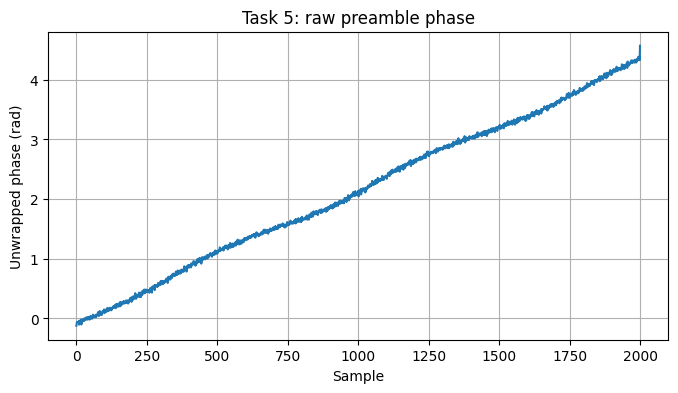

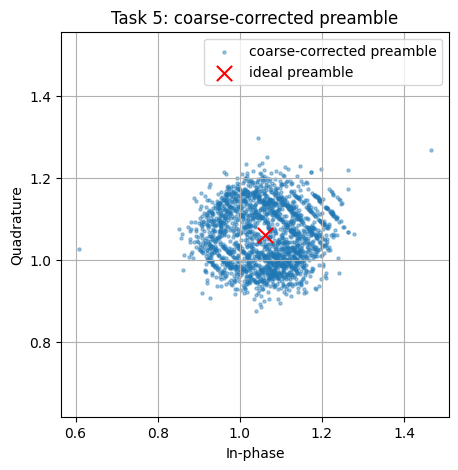

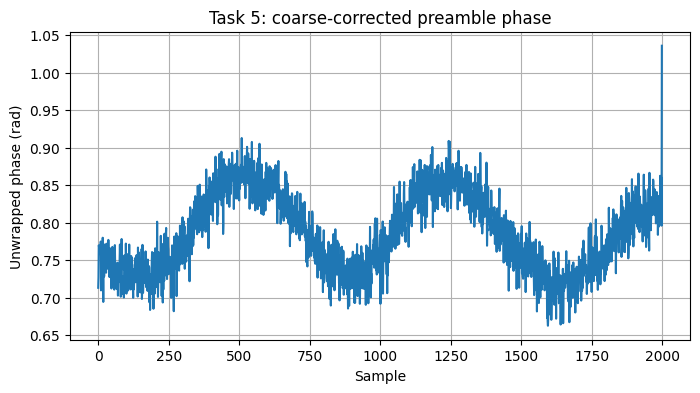

Fine residual CFO from BPSK squaring: -29.881914 Hz


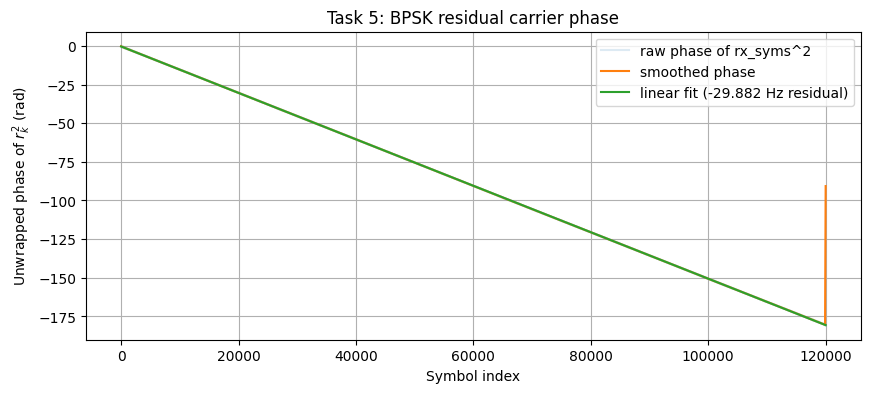

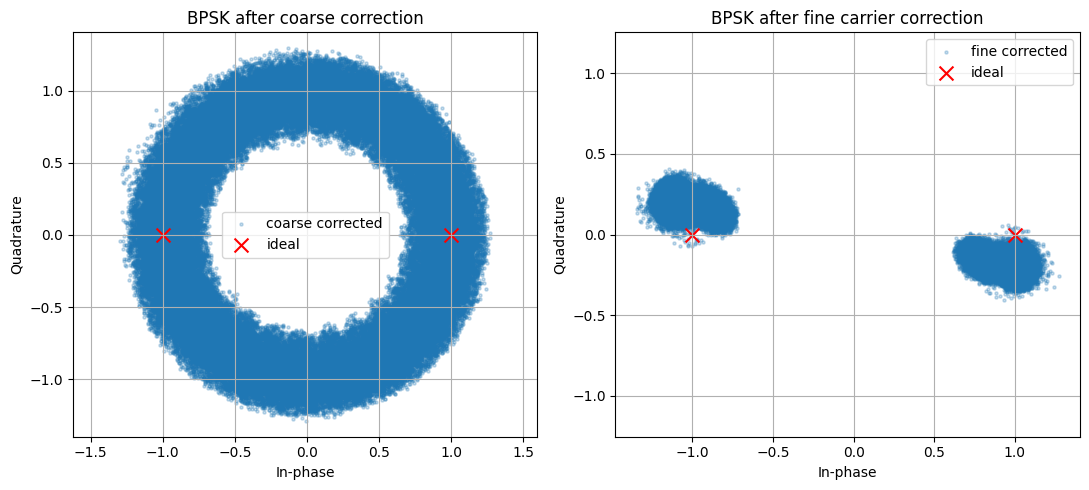

In [8]:
def find_frame_start(rx_samples, preamble_len, frame_len, search_stride=1):
    """Find the start of the high-power preamble at sample resolution."""
    n = len(rx_samples) - frame_len
    best_start, best_power = 0, -np.inf

    for start in range(0, max(n + 1, 1), search_stride):
        window = rx_samples[start:start + preamble_len]
        if len(window) != preamble_len:
            continue

        power = np.mean(np.abs(window) ** 2)
        if power > best_power:
            best_power = power
            best_start = start

    return best_start


def correct_frame(frame_slice, preamble_len, preamble_symbol, preamble_scale, fs):
    """Estimate coarse CFO from the constant preamble, then correct CFO, phase and gain."""
    preamble_rx = frame_slice[:preamble_len]

    # ------------------------------------------------------------
    # Coarse CFO estimation from the unwrapped preamble phase slope
    # ------------------------------------------------------------
    n_pre = np.arange(preamble_len)
    raw_phase = np.unwrap(np.angle(preamble_rx))
    phase_slope, phase_intercept = np.polyfit(n_pre, raw_phase, 1)
    f_offset_hat = phase_slope * fs / (2 * np.pi)

    # ------------------------------------------------------------
    # Coarse CFO correction
    # ------------------------------------------------------------
    n = np.arange(len(frame_slice))
    cfo_corrected = frame_slice * np.exp(
        -1j * 2 * np.pi * f_offset_hat * n / fs
    )

    # ------------------------------------------------------------
    # Phase + amplitude correction using the known preamble
    # ------------------------------------------------------------
    ref = np.mean(cfo_corrected[:preamble_len])
    ideal_preamble = preamble_scale * preamble_symbol

    phase_offset_hat = np.angle(ref) - np.angle(ideal_preamble)
    gain_hat = np.abs(ref) / np.abs(ideal_preamble)

    corrected = (
        cfo_corrected
        * np.exp(-1j * phase_offset_hat)
        / gain_hat
    )

    return corrected, f_offset_hat, phase_offset_hat, gain_hat


# ------------------------------------------------------------
# Task 5: BPSK frame synchronization and coarse correction
# ------------------------------------------------------------
start = find_frame_start(
    raw_rx_samples,
    preamble_len,
    demo_frame_len,
    search_stride=1
)

frame_slice = raw_rx_samples[start:start + demo_frame_len]
preamble_symbol = (1 + 1j) / np.sqrt(2)

corrected, f_hat, phi_hat, g_hat = correct_frame(
    frame_slice,
    preamble_len,
    preamble_symbol,
    preamble_scale,
    fs
)

# Diagnostics for frame alignment and coarse correction
raw_phase = np.unwrap(np.angle(frame_slice[:preamble_len]))
corrected_phase = np.unwrap(np.angle(corrected[:preamble_len]))

raw_slope = np.polyfit(np.arange(preamble_len), raw_phase, 1)[0]
corrected_slope = np.polyfit(np.arange(preamble_len), corrected_phase, 1)[0]

print(f"Detected frame start: {start}")
print(f"Frame start modulo sps: {start % sps}")
print(f"Estimated coarse CFO: {f_hat:.6f} Hz")
print(f"Estimated phase offset: {phi_hat:.6f} rad")
print(f"Estimated gain: {g_hat:.6f}")
print(f"Raw preamble phase slope: {raw_slope:.6e} rad/sample")
print(f"Coarse-corrected preamble phase slope: {corrected_slope:.6e} rad/sample")

# ------------------------------------------------------------
# Diagnostic 1: raw preamble phase
# ------------------------------------------------------------
plt.figure(figsize=(8, 4))
plt.plot(raw_phase)
plt.grid(True)
plt.xlabel('Sample')
plt.ylabel('Unwrapped phase (rad)')
plt.title('Task 5: raw preamble phase')
plt.show()

# ------------------------------------------------------------
# Diagnostic 2: coarse-corrected preamble constellation
# ------------------------------------------------------------
plt.figure(figsize=(5, 5))
plt.scatter(
    corrected[:preamble_len].real,
    corrected[:preamble_len].imag,
    s=5,
    alpha=0.4,
    label='coarse-corrected preamble'
)

ref_point = preamble_scale * preamble_symbol
plt.scatter(
    [ref_point.real],
    [ref_point.imag],
    s=120,
    marker='x',
    c='red',
    label='ideal preamble'
)

plt.axis('equal')
plt.grid(True)
plt.legend()
plt.xlabel('In-phase')
plt.ylabel('Quadrature')
plt.title('Task 5: coarse-corrected preamble')
plt.show()

# ------------------------------------------------------------
# Diagnostic 3: coarse-corrected preamble phase
# ------------------------------------------------------------
plt.figure(figsize=(8, 4))
plt.plot(corrected_phase)
plt.grid(True)
plt.xlabel('Sample')
plt.ylabel('Unwrapped phase (rad)')
plt.title('Task 5: coarse-corrected preamble phase')
plt.show()

# ------------------------------------------------------------
# Matched-filtered BPSK symbols after coarse correction
# ------------------------------------------------------------
rx_syms = matched_filter_downsample(
    corrected[preamble_len:],
    rect_pulse(sps),
    sps
)

# ------------------------------------------------------------
# Fine carrier estimation using BPSK squaring
#
# For BPSK, x_k in {+1,-1}; therefore x_k^2 = 1.
# Squaring removes the data modulation and leaves twice the
# residual carrier phase. A moving average suppresses symbol noise
# before estimating the residual phase slope.
# ------------------------------------------------------------
z = rx_syms ** 2
phase2 = np.unwrap(np.angle(z))

smooth_window = 201
if len(phase2) <= 2 * smooth_window:
    raise ValueError("Payload is too short for the selected fine-CFO smoothing window.")

kernel = np.ones(smooth_window) / smooth_window
phase2_smooth = np.convolve(phase2, kernel, mode='same')

# Ignore convolution edge effects when fitting the residual slope.
fit_start = smooth_window
fit_end = len(phase2) - smooth_window
k = np.arange(len(phase2))

fine_phase_slope_2, fine_phase_intercept_2 = np.polyfit(
    k[fit_start:fit_end],
    phase2_smooth[fit_start:fit_end],
    1
)

# phase2 = 2*pi*(2*f_residual/Rs)*k + const
# => f_residual = slope * Rs / (4*pi)
symbol_rate = fs / sps
fine_cfo_hat = fine_phase_slope_2 * symbol_rate / (4 * np.pi)

print(f"Fine residual CFO from BPSK squaring: {fine_cfo_hat:.6f} Hz")

# ------------------------------------------------------------
# Diagnostic 4: squared-BPSK residual phase
# ------------------------------------------------------------
plt.figure(figsize=(10, 4))
plt.plot(phase2, alpha=0.15, label='raw phase of rx_syms^2')
plt.plot(phase2_smooth, label='smoothed phase')
plt.plot(
    k,
    fine_phase_slope_2 * k + fine_phase_intercept_2,
    label=f'linear fit ({fine_cfo_hat:.3f} Hz residual)'
)
plt.xlabel('Symbol index')
plt.ylabel('Unwrapped phase of $r_k^2$ (rad)')
plt.title('Task 5: BPSK residual carrier phase')
plt.grid(True)
plt.legend()
plt.show()

# ------------------------------------------------------------
# Fine carrier correction
# ------------------------------------------------------------
# Work at the symbol rate. The fitted phase of r^2 is twice the
# carrier phase, so divide by two before applying the correction.
residual_phase = 0.5 * (
    fine_phase_slope_2 * k + fine_phase_intercept_2
)

# Remove only the phase evolution. The preamble-based phase/gain
# correction above already establishes the initial reference.
residual_phase_relative = residual_phase - residual_phase[0]

rx_syms_fine = rx_syms * np.exp(-1j * residual_phase_relative)

ideal = np.array(list(CONSTELLATIONS['BPSK'].values()))

# ------------------------------------------------------------
# Diagnostic 5: BPSK constellation before and after fine correction
# ------------------------------------------------------------
fig = plt.figure(figsize=(11, 5))

ax1 = fig.add_subplot(1, 2, 1)
ax1.scatter(
    rx_syms.real,
    rx_syms.imag,
    s=5,
    alpha=0.25,
    label='coarse corrected'
)
ax1.scatter(
    ideal.real,
    ideal.imag,
    s=100,
    marker='x',
    c='red',
    label='ideal'
)
ax1.axis('equal')
ax1.grid(True)
ax1.set_xlabel('In-phase')
ax1.set_ylabel('Quadrature')
ax1.set_title('BPSK after coarse correction')
ax1.legend()

ax2 = fig.add_subplot(1, 2, 2)
ax2.scatter(
    rx_syms_fine.real,
    rx_syms_fine.imag,
    s=5,
    alpha=0.25,
    label='fine corrected'
)
ax2.scatter(
    ideal.real,
    ideal.imag,
    s=100,
    marker='x',
    c='red',
    label='ideal'
)
ax2.axis('equal')
ax2.grid(True)
ax2.set_xlabel('In-phase')
ax2.set_ylabel('Quadrature')
ax2.set_title('BPSK after fine carrier correction')
ax2.legend()

plt.tight_layout()
plt.show()


### Task 5 debugging note

The frame search uses a 1-sample stride, so synchronization is not limited to 50-sample increments. The coarse correction uses the constant preamble. The fine correction uses $r_k^2$ after matched filtering; for BPSK, squaring removes the $\pm1$ data modulation and exposes the residual carrier phase. The final `rx_syms_fine` constellation is the diagnostic result to compare with the expected two clusters at $\pm1$.


## Task 6: Estimating SNR From the Preamble

Lab 3's Bonus admitted that receiver gain isn't $E_b/N_0$, and left it there. Here's the fix:
the preamble is a *known, constant* transmitted value, which makes it a built-in noise probe
-- the same idea as Lab 1's IQ noise analysis, just applied to one segment of one frame
instead of an idle capture.

After correction (Task 5), the preamble segment should sit at one point. It doesn't, exactly
-- whatever it's scattered around that point *is* the noise.

Checklist:
- `estimate_snr(corrected_frame, preamble_len)`:
  - Take the mean of the corrected preamble segment as your signal reference.
  - Signal power = $|\text{reference}|^2$.
  - Noise power = the average squared deviation of individual preamble samples from that
    reference.
  - Return SNR as a ratio (not dB) -- you'll want the linear value for Task 8's $E_b/N_0$
    bookkeeping.
- This is a *per-sample* SNR, measured before matched filtering. Task 3's matched filter
  averages `sps` samples per symbol -- given that, and assuming sample-to-sample noise is
  independent, what should happen to SNR after matched filtering? You'll need this for
  Task 8.

In [9]:
def estimate_snr(corrected_frame, preamble_len):
    '''
    TODO:
      1. reference = mean of corrected_frame[:preamble_len]
      2. signal_power = |reference|^2
      3. noise_power = mean(|corrected_frame[:preamble_len] - reference|^2)
      4. return signal_power / noise_power
    '''
    preamble_segment = corrected_frame[:preamble_len]
    reference = np.mean(preamble_segment)
    signal_power = np.abs(reference)**2
    noise_power = np.mean(np.abs(preamble_segment - reference)**2)
    return signal_power / noise_power


snr_est = estimate_snr(corrected, preamble_len)
print(f"Per-sample SNR estimate: {snr_est:.2f} ({10*np.log10(snr_est):.1f} dB)")

Per-sample SNR estimate: 181.71 (22.6 dB)


## Task 7: Probability of Error vs. SNR, for BPSK

Same single-frame discipline as Lab 3: one sized frame, one capture, one BER number, no
pooling. The difference this time is what's on the x-axis. Instead of sweeping RX gain and
reading BER off against an arbitrary knob, sweep `tx_sdr.tx_hardwaregain_chan0` (TX
attenuation) with RX gain **held fixed** -- that changes signal power without changing the
receiver's own noise floor, which is what makes "SNR" a meaningful, controllable quantity here
instead of a hopeful correlate of one.

`run_trial` below is the same glue pattern as Lab 3's -- given -- but it now also returns the
SNR estimate from Task 6 alongside the BER. `compute_ber` is your last TODO on the measurement
side.

**Implementation note:** `compute_ber` is defined in the following code cell before
`run_trial` calls it. For BPSK, `run_trial` also applies the fine carrier correction
from Task 5 before symbol decisions, which is required for the long 120,000-bit frame.


In [12]:
def compute_ber(tx_bits, rx_bits):
    """
    Compare transmitted and received bits.

    If the two arrays have different lengths, compare only the common
    portion. Returns:
        (number_of_errors, total_bits_compared, BER)
    """
    min_len = min(len(tx_bits), len(rx_bits))

    if min_len == 0:
        return 0, 0, 0.0

    tx = np.asarray(tx_bits[:min_len], dtype=np.uint8)
    rx = np.asarray(rx_bits[:min_len], dtype=np.uint8)

    num_errors = int(np.sum(tx != rx))
    total_bits = int(min_len)
    ber = num_errors / total_bits

    return num_errors, total_bits, ber


def fine_carrier_correct_bpsk(rx_syms, fs, sps, smooth_window=201):
    """
    Fine carrier correction for BPSK using the squaring method.

    For BPSK, b[k] is approximately +/-1, so:
        (b[k] * exp(j*theta[k]))^2 = exp(j*2*theta[k])

    Therefore the phase of rx_syms**2 contains the residual carrier phase
    while the BPSK data modulation is removed.
    """
    if len(rx_syms) <= 2 * smooth_window:
        raise ValueError("Payload is too short for the selected fine-CFO smoothing window.")

    z = rx_syms ** 2
    phase2 = np.unwrap(np.angle(z))

    kernel = np.ones(smooth_window) / smooth_window
    phase2_smooth = np.convolve(phase2, kernel, mode='same')

    k = np.arange(len(rx_syms))

    fit_start = smooth_window
    fit_end = len(rx_syms) - smooth_window

    slope2, intercept2 = np.polyfit(
        k[fit_start:fit_end],
        phase2_smooth[fit_start:fit_end],
        1
    )

    symbol_rate = fs / sps

    # phase2 slope = 4*pi*f_residual/Rs
    fine_cfo_hat = slope2 * symbol_rate / (4 * np.pi)

    # The carrier phase is half of the squared-signal phase.
    residual_phase = 0.5 * (slope2 * k + intercept2)

    # Keep the phase reference established by the coarse correction.
    residual_phase_relative = residual_phase - residual_phase[0]

    rx_syms_fine = rx_syms * np.exp(-1j * residual_phase_relative)

    return rx_syms_fine, fine_cfo_hat, phase2, phase2_smooth, slope2, intercept2


def run_trial(scheme, tx_gain_db, tx_bits):
    tx_frame, used_bits = build_tx_frame(
        tx_bits, scheme, sps, preamble_len, preamble_scale
    )
    frame_len = frame_len_for(
        scheme, used_bits, preamble_len, sps
    )

    tx_sdr.tx_hardwaregain_chan0 = tx_gain_db
    time.sleep(0.1)

    rx_samples = capture(
        tx_frame,
        buffer_size_for(frame_len)
    )

    start = find_frame_start(
        rx_samples,
        preamble_len,
        frame_len,
        search_stride=1
    )

    if start + frame_len > len(rx_samples):
        raise ValueError("Complete frame was not found in the RX capture.")

    frame_slice = rx_samples[start:start + frame_len]

    preamble_symbol = (1 + 1j) / np.sqrt(2)

    # Coarse CFO + phase + amplitude correction.
    corrected, f_hat, phi_hat, g_hat = correct_frame(
        frame_slice,
        preamble_len,
        preamble_symbol,
        preamble_scale,
        fs
    )

    # Task 6 SNR is evaluated on the preamble after coarse correction.
    snr_hat = estimate_snr(
        corrected,
        preamble_len
    )

    # Matched filter and symbol-rate sampling.
    rx_syms = matched_filter_downsample(
        corrected[preamble_len:],
        rect_pulse(sps),
        sps
    )

    # Fine carrier correction for BPSK.
    if scheme == 'BPSK':
        rx_syms, fine_cfo_hat, _, _, _, _ = fine_carrier_correct_bpsk(
            rx_syms,
            fs,
            sps,
            smooth_window=201
        )
    else:
        fine_cfo_hat = np.nan

    # Convert corrected symbols to bits.
    rx_bits = symbols_to_bits(
        rx_syms,
        scheme
    )

    errors, total, ber = compute_ber(
        used_bits,
        rx_bits
    )

    return ber, total, snr_hat


# Single test call before committing to the full sweep.
ber, total_bits, snr_hat = run_trial(
    'BPSK',
    -20,
    tx_bits
)

print(
    f"BPSK @ -20 dB TX gain: "
    f"BER={ber:.4f}, "
    f"bits={total_bits}, "
    f"SNR={10*np.log10(snr_hat):.1f} dB"
)


BPSK @ -20 dB TX gain: BER=0.0000, bits=120000, SNR=23.3 dB


In [20]:
# TX buffer cleanup is handled by the next transmission.
tx_sdr.tx_destroy_buffer()


## Task 7: BPSK SNR/BER sweep

The `run_trial()` function below includes the same fine BPSK carrier correction used in Task 5, so the measured BER is computed after both coarse and fine carrier recovery.

In [21]:
# ============================================================
# TASK 7: BER vs TX GAIN SWEEP
# ============================================================

tx_gain_values = np.arange(-60, -9, 4, dtype=float)

ber_values = []
snr_values = []

for i, gain in enumerate(tx_gain_values):

    print(
        f"Running trial {i+1}/{len(tx_gain_values)} "
        f"for TX gain: {gain:.1f} dB"
    )

    try:
        # Run one complete TX/RX trial
        ber, total_bits, snr_hat = run_trial(
            'BPSK',
            float(gain),
            tx_bits
        )

        ber_values.append(ber)
        snr_values.append(
            10 * np.log10(snr_hat)
            if np.isfinite(snr_hat) and snr_hat > 0
            else np.nan
        )

        print(
            f"  BER={ber:.6f}, "
            f"bits={total_bits}, "
            f"SNR={snr_values[-1]:.2f} dB"
        )

    except Exception as e:

        print(
            f"  Trial failed for TX gain {gain:.1f} dB: "
            f"{e}. Appending NaN."
        )

        ber_values.append(np.nan)
        snr_values.append(np.nan)

    finally:
        # ----------------------------------------------------
        # Destroy the cyclic TX buffer BEFORE the next trial.
        # This is required because capture() uses cyclic TX.
        # ----------------------------------------------------
        try:
            tx_sdr.tx_destroy_buffer()
            print("  TX cyclic buffer destroyed.")
        except Exception as e:
            print(f"  TX buffer cleanup: {e}")

print("Trials complete.")

Running trial 1/13 for TX gain: -60.0 dB
  BER=0.500492, bits=120000, SNR=-17.02 dB
  TX cyclic buffer destroyed.
Running trial 2/13 for TX gain: -56.0 dB
  BER=0.518933, bits=120000, SNR=6.79 dB
  TX cyclic buffer destroyed.
Running trial 3/13 for TX gain: -52.0 dB
  BER=0.000000, bits=120000, SNR=10.10 dB
  TX cyclic buffer destroyed.
Running trial 4/13 for TX gain: -48.0 dB
  BER=0.000000, bits=120000, SNR=14.30 dB
  TX cyclic buffer destroyed.
Running trial 5/13 for TX gain: -44.0 dB
  BER=0.000000, bits=120000, SNR=17.40 dB
  TX cyclic buffer destroyed.
Running trial 6/13 for TX gain: -40.0 dB
  BER=0.000000, bits=120000, SNR=20.20 dB
  TX cyclic buffer destroyed.
Running trial 7/13 for TX gain: -36.0 dB
  BER=0.000000, bits=120000, SNR=23.11 dB
  TX cyclic buffer destroyed.
Running trial 8/13 for TX gain: -32.0 dB
  BER=0.000000, bits=120000, SNR=20.51 dB
  TX cyclic buffer destroyed.
Running trial 9/13 for TX gain: -28.0 dB
  BER=0.000000, bits=120000, SNR=21.83 dB
  TX cyclic b

## Task 8: Measured vs. Theoretical $P_b$

For BPSK in AWGN, $P_b = Q(\sqrt{2 E_b/N_0})$. You have `snr_results` -- a *per-sample* SNR,
from Task 6 -- and you reasoned in Task 6 about what matched filtering (averaging `sps`
samples) does to it. Use that relationship to convert your per-sample SNR estimates into
$E_b/N_0$, then plot your measured BER against the theoretical curve on the same axes.

Checklist:
- Convert each entry of `snr_results` (linear, per-sample) into an estimated $E_b/N_0$.
- Compute the theoretical curve $Q(\sqrt{2 E_b/N_0})$ over a smooth, densely-sampled range of
  $E_b/N_0$ spanning your measured points. ($Q(x) = \tfrac{1}{2}\,\text{erfc}(x/\sqrt{2})$;
  `erfc` is already imported at the top of this notebook.)
- `plt.semilogy`: measured BER as points/markers, theoretical curve as a line, both against
  $E_b/N_0$ in dB. Legend, labels, grid.
- Where do measured and theoretical agree well, and where do they diverge? Keep your answer
  in mind for the Bonus section.

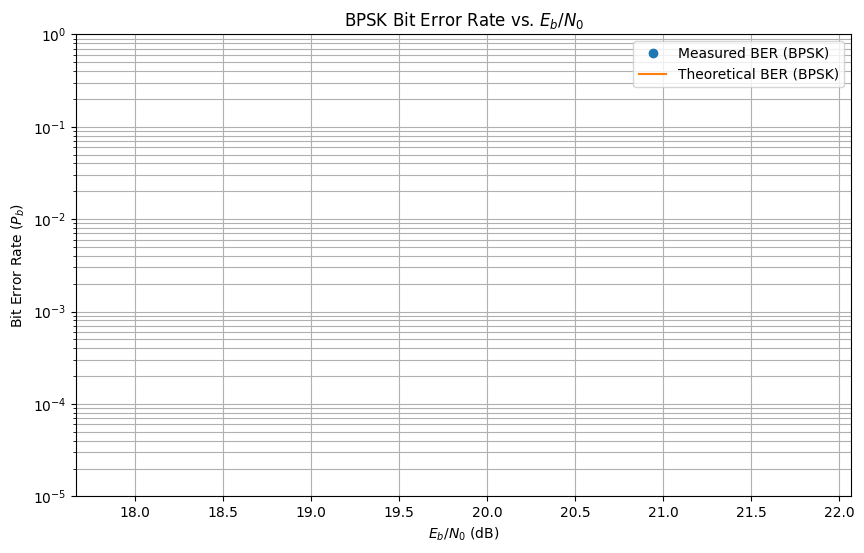

In [22]:
def Q(x):
    return 0.5 * erfc(x / np.sqrt(2))

# 1. ebn0_linear = np.array(snr_results) * sps    (per-sample SNR -> post-matched-filter
#    Eb/N0, using your Task 6 reasoning -- BPSK carries 1 bit/symbol, so Es/N0 == Eb/N0)
ebn0_linear = np.array(snr_results) * sps

# 2. ebn0_db = 10 * np.log10(ebn0_linear)
ebn0_db = 10 * np.log10(ebn0_linear)

# 3. ebn0_theory_db = np.linspace(ebn0_db.min() - 2, ebn0_db.max() + 2, 200)
#    pb_theory = Q(np.sqrt(2 * 10**(ebn0_theory_db / 10)))

# Filter out NaN values from ebn0_db for min/max calculation to avoid issues
valid_ebn0_db = ebn0_db[~np.isnan(ebn0_db)]

if len(valid_ebn0_db) > 0:
    min_ebn0 = valid_ebn0_db.min() - 2
    max_ebn0 = valid_ebn0_db.max() + 2
    ebn0_theory_db = np.linspace(min_ebn0, max_ebn0, 200)
    pb_theory = Q(np.sqrt(2 * 10**(ebn0_theory_db / 10)))

    # 4. plt.semilogy(ebn0_db, ber_results, 'o', label='measured')
    #    plt.semilogy(ebn0_theory_db, pb_theory, '-', label='theory: Q(sqrt(2 Eb/N0))')
    #    ... axis labels ('Eb/N0 (dB)', 'Bit Error Rate'), legend, grid, title ...
    plt.figure(figsize=(10, 6))
    plt.semilogy(ebn0_db, ber_results, 'o', label='Measured BER (BPSK)')
    plt.semilogy(ebn0_theory_db, pb_theory, '-', label='Theoretical BER (BPSK)')
    plt.xlabel('$E_b/N_0$ (dB)')
    plt.ylabel('Bit Error Rate ($P_b$)')
    plt.title('BPSK Bit Error Rate vs. $E_b/N_0$')
    plt.grid(True, which="both", ls="-")
    plt.legend()
    plt.ylim(1e-5, 1) # Set reasonable y-limits for BER plots
    plt.show()
else:
    print("No valid SNR results to plot. Please check the trials.")

# Part 2: From One Axis to Two -- Combined 4-ASK / 2-ASK, and 4-ASK on Hardware

Every scheme in Lab 3 varied phase, or phase-and-amplitude together, but never treated the two
IQ axes as independent. They don't have to be tied together: nothing stops you from running
one amplitude modulation on the in-phase axis and a completely different one on quadrature.

This part builds that idea in two stages. First, entirely in simulation (no hardware, no
Plutos) -- 4-ASK on the x-axis, 2-ASK on the y-axis, combined into one 8-point rectangular
constellation, 3 bits/symbol. Once you understand how that constellation behaves, you'll put
the simpler half of it -- 4-ASK by itself, one axis, one Pluto pair -- back on the air, reusing
every piece of machinery from Part 1.

## Task 9: Build the 4-ASK x 2-ASK Constellation

Pure computation -- no SDR calls anywhere in this task.

- 4-ASK on the in-phase axis: four equally-spaced real amplitude levels.
- 2-ASK on the quadrature axis: two equally-spaced real amplitude levels. (What modulation
  scheme, already in `CONSTELLATIONS`, is 2-ASK equivalent to, once you allow the two levels
  to sit on whichever axis you like?)
- Combine them: every (I-level, Q-level) pair is one point of an 8-point constellation.
- Normalize the whole 8-point set to unit average symbol energy.
- Gray-code it: assign each point a 3-bit label such that points differing in only one
  coordinate (adjacent along I, or adjacent along Q) differ in exactly one bit. Diagonal
  neighbors are not required to satisfy this -- think about why not, and keep your answer for
  the Theoretical Questions.
- Register the result as `CONSTELLATIONS['ASK4x2']` and `BITS_PER_SYMBOL['ASK4x2'] = 3`.
- Produce a labeled IQ scatter plot: each point, annotated with its 3-bit label.

No further hints beyond what Lab 3 Task 2 already taught you about constructing and
Gray-coding a constellation -- you're applying the same skill to two axes instead of one.

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


ASK4x2 CONSTELLATION
Raw average symbol energy : 6.000000
Normalization factor      : 2.449490
Normalized average energy : 1.000000
Bits per symbol           : 3

 Label       I              Q          Complex symbol
------------------------------------------------------------
  000       -1.224745       -0.408248       -1.224745 -0.408248j
  001       -1.224745       +0.408248       -1.224745 +0.408248j
  010       -0.408248       -0.408248       -0.408248 -0.408248j
  011       -0.408248       +0.408248       -0.408248 +0.408248j
  110       +0.408248       -0.408248       +0.408248 -0.408248j
  111       +0.408248       +0.408248       +0.408248 +0.408248j
  100       +1.224745       -0.408248       +1.224745 -0.408248j
  101       +1.224745       +0.408248       +1.224745 +0.408248j


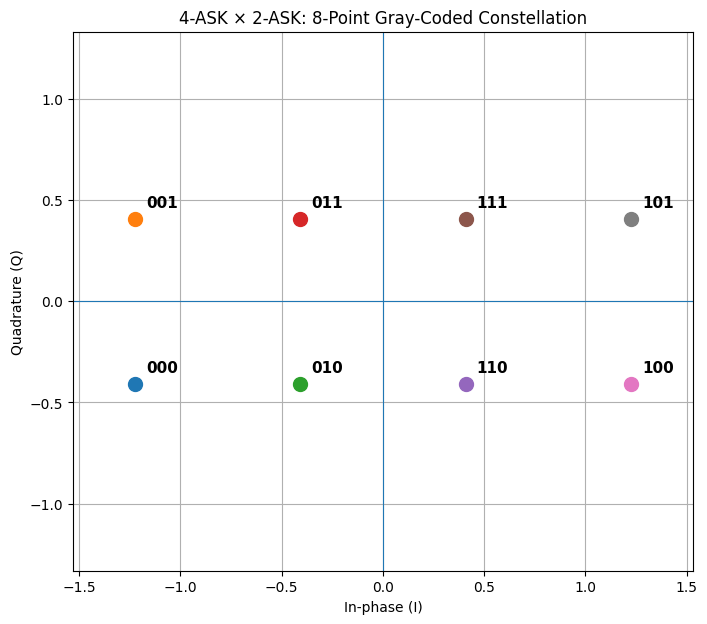


TASK 9 SANITY CHECKS
8 constellation points       : True
3 bits/symbol                : True
Unit average symbol energy   : True
2-ASK equivalent to BPSK     : YES

CONSTELLATIONS['ASK4x2'] successfully registered.
BITS_PER_SYMBOL['ASK4x2'] = 3


In [23]:
# ============================================================
# TASK 9: Build the 4-ASK x 2-ASK Constellation
# ============================================================
# Pure computation -- NO SDR calls.
#
# 4-ASK on I:
#     [-3, -1, +1, +3]
#
# 2-ASK on Q:
#     [-1, +1]
#
# Gray coding:
#     I axis: 00, 01, 11, 10
#     Q axis:  0,  1
#
# Combined 3-bit label:
#     [2 I bits][1 Q bit]
#
# This guarantees:
#   - adjacent I points differ by 1 bit
#   - adjacent Q points differ by 1 bit
#   - diagonal neighbors are allowed to differ by 2 bits
#
# Finally, the entire 8-point constellation is normalized so
# average symbol energy = 1.
# ============================================================


# ------------------------------------------------------------
# 1. Define the independent ASK amplitude levels
# ------------------------------------------------------------

# Four equally spaced levels on the I axis.
# Symmetric 4-ASK levels are chosen as:
#     -3, -1, +1, +3
I_levels = np.array([-3.0, -1.0, 1.0, 3.0])

# Two equally spaced levels on the Q axis.
# This is equivalent to BPSK when placed on the Q axis.
Q_levels = np.array([-1.0, 1.0])


# ------------------------------------------------------------
# 2. Define Gray labels independently on each axis
# ------------------------------------------------------------

# Standard 4-level Gray ordering:
#
# amplitude       Gray label
#    -3              00
#    -1              01
#    +1              11
#    +3              10
#
I_gray = {
    -3.0: "00",
    -1.0: "01",
     1.0: "11",
     3.0: "10"
}

# 2-ASK Gray ordering.
#
# amplitude       Gray label
#    -1               0
#    +1               1
#
Q_gray = {
    -1.0: "0",
     1.0: "1"
}


# ------------------------------------------------------------
# 3. Construct all 8 I/Q combinations
# ------------------------------------------------------------

points = []

for i_level in I_levels:
    for q_level in Q_levels:

        # Concatenate the 2-bit I label and 1-bit Q label.
        label = I_gray[i_level] + Q_gray[q_level]

        # Complex baseband representation:
        #     symbol = I + jQ
        symbol = complex(i_level, q_level)

        points.append((label, symbol))


# ------------------------------------------------------------
# 4. Normalize the COMPLETE 8-point constellation
# ------------------------------------------------------------

# Calculate average symbol energy BEFORE normalization:
#
#     E_avg = mean(|s|^2)
#
# where:
#
#     |s|^2 = I^2 + Q^2
#
raw_symbols = np.array(
    [symbol for label, symbol in points],
    dtype=np.complex128
)

raw_avg_energy = np.mean(np.abs(raw_symbols) ** 2)

if not np.isfinite(raw_avg_energy) or raw_avg_energy <= 0:
    raise ValueError("Invalid average symbol energy during ASK4x2 construction.")

# Scale all points so:
#
#     mean(|s_normalized|^2) = 1
#
normalization_factor = np.sqrt(raw_avg_energy)

normalized_symbols = raw_symbols / normalization_factor


# ------------------------------------------------------------
# 5. Build the final CONSTELLATIONS dictionary
# ------------------------------------------------------------

# Make sure the existing dictionaries exist.
if "CONSTELLATIONS" not in globals():
    CONSTELLATIONS = {}

if "BITS_PER_SYMBOL" not in globals():
    BITS_PER_SYMBOL = {}

# Register ASK4x2.
CONSTELLATIONS["ASK4x2"] = {
    label: symbol
    for (label, _), symbol in zip(points, normalized_symbols)
}

# 8 points -> log2(8) = 3 bits/symbol.
BITS_PER_SYMBOL["ASK4x2"] = 3


# ------------------------------------------------------------
# 6. Verify the constellation
# ------------------------------------------------------------

ask4x2_symbols = np.array(
    list(CONSTELLATIONS["ASK4x2"].values()),
    dtype=np.complex128
)

ask4x2_labels = list(
    CONSTELLATIONS["ASK4x2"].keys()
)

avg_energy = np.mean(np.abs(ask4x2_symbols) ** 2)

if len(ask4x2_symbols) != 8:
    raise AssertionError(
        f"ASK4x2 must contain 8 points, found {len(ask4x2_symbols)}."
    )

if BITS_PER_SYMBOL["ASK4x2"] != 3:
    raise AssertionError("ASK4x2 must carry exactly 3 bits/symbol.")

if not np.isclose(avg_energy, 1.0, atol=1e-12):
    raise AssertionError(
        f"ASK4x2 average symbol energy is {avg_energy}, expected 1."
    )


# ------------------------------------------------------------
# 7. Print the resulting constellation
# ------------------------------------------------------------

print("=" * 60)
print("ASK4x2 CONSTELLATION")
print("=" * 60)

print(f"Raw average symbol energy : {raw_avg_energy:.6f}")
print(f"Normalization factor      : {normalization_factor:.6f}")
print(f"Normalized average energy : {avg_energy:.6f}")
print(f"Bits per symbol           : {BITS_PER_SYMBOL['ASK4x2']}")
print()

print(" Label       I              Q          Complex symbol")
print("-" * 60)

# Sort by I coordinate, then Q coordinate for readable output.
sorted_items = sorted(
    CONSTELLATIONS["ASK4x2"].items(),
    key=lambda item: (item[1].real, item[1].imag)
)

for label, symbol in sorted_items:
    print(
        f"  {label}       "
        f"{symbol.real:+.6f}       "
        f"{symbol.imag:+.6f}       "
        f"{symbol.real:+.6f} {symbol.imag:+.6f}j"
    )


# ------------------------------------------------------------
# 8. Labeled IQ scatter plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

for label, symbol in sorted_items:

    plt.scatter(
        symbol.real,
        symbol.imag,
        s=100
    )

    # Slight offset so the label does not cover the marker.
    plt.annotate(
        label,
        (symbol.real, symbol.imag),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold"
    )

# Reference axes
plt.axhline(
    0,
    linewidth=0.8
)

plt.axvline(
    0,
    linewidth=0.8
)

plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("4-ASK × 2-ASK: 8-Point Gray-Coded Constellation")

plt.grid(True)
plt.axis("equal")

# Add a little padding around the constellation.
max_extent = np.max(
    np.abs(
        np.concatenate([
            ask4x2_symbols.real,
            ask4x2_symbols.imag
        ])
    )
)

padding = 0.25 * max_extent

plt.xlim(
    ask4x2_symbols.real.min() - padding,
    ask4x2_symbols.real.max() + padding
)

plt.ylim(
    ask4x2_symbols.imag.min() - padding,
    ask4x2_symbols.imag.max() + padding
)

plt.show()


# ------------------------------------------------------------
# 9. Final sanity checks
# ------------------------------------------------------------

print()
print("=" * 60)
print("TASK 9 SANITY CHECKS")
print("=" * 60)

print(
    "8 constellation points       :",
    len(CONSTELLATIONS["ASK4x2"]) == 8
)

print(
    "3 bits/symbol                :",
    BITS_PER_SYMBOL["ASK4x2"] == 3
)

print(
    "Unit average symbol energy   :",
    np.isclose(avg_energy, 1.0, atol=1e-12)
)

print(
    "2-ASK equivalent to BPSK     :",
    "YES"
)

print()
print("CONSTELLATIONS['ASK4x2'] successfully registered.")
print("BITS_PER_SYMBOL['ASK4x2'] =", BITS_PER_SYMBOL["ASK4x2"])

# Background: Matched Filtering, SNR, and Multilevel Constellations

**Why the matched filter maximizes SNR.** Suppose you transmit one symbol as $s[n] = a\,g[n]$
for $n = 0, \dots, sps-1$, and receive $r[n] = s[n] + w[n]$ with $w[n]$ white noise of variance
$\sigma^2$. A linear receiver forms a single decision statistic $y = \sum_n h[n]\, r[n]$ for
some filter $h[n]$, and you want to choose $h$ to make $y$ as reliable an estimate of $a$ as
possible -- i.e. maximize $|\mathbb{E}[y]|^2 / \text{Var}(y)$. By the Cauchy-Schwarz
inequality, this ratio is maximized when $h[n] \propto g^*[-n]$ -- the time-reversed,
conjugated pulse -- which is exactly why it's called "matched." For a rectangular $g[n]$,
time-reversal does nothing (it's symmetric), so the matched filter is the same rectangular
shape: a plain average over the symbol.

**Processing gain, concretely.** Averaging `sps` independent noisy samples of the same
transmitted value divides the *noise* variance by `sps` while leaving the signal untouched --
the output SNR is `sps` times the input, per-sample SNR. This is why Task 6 asked you to
measure SNR on the raw preamble (before matched filtering) and separately reason about what
happens after: the two numbers are related by exactly this factor, and only the post-filter
one belongs in $E_b/N_0$.

**Why TX gain, not RX gain, sweeps SNR cleanly.** Receiver gain amplifies the signal *and*
whatever noise has already entered the front end by the time that gain stage acts on it --
raising RX gain mostly doesn't change SNR, until you're close enough to the ADC's noise floor
or full-scale limit that nonlinear effects start to dominate (which is exactly the "gets worse
again" behavior Lab 3's Bonus asked you to notice). Transmit power, on the other hand, changes
signal power at the receiver without touching the receiver's own noise floor at all -- a much
cleaner independent variable for an SNR sweep, at the cost of needing a receiver that isn't
already saturated or buried in noise at either end of the range.

**Independent axes, and where Gray coding stops being free.** A constellation with $M$ levels
on I and $N$ levels on Q, each individually Gray-coded, is not automatically fully Gray-coded
as a 2-D whole: two points that are diagonal neighbors (adjacent in *both* I and Q at once)
differ in two bits, not one, because they're two single-axis steps apart, each costing one bit
flip. This is the same "most likely error costs one bit" idea from Lab 3's Background, applied
per-axis instead of globally -- it degrades gracefully rather than breaking, because at
reasonable SNR the dominant error mode is still a single-axis nearest-neighbor slip, not a
diagonal one.

**Symbol energy for a combined constellation.** For independent $M$-level and $N$-level ASK on
I and Q respectively, with levels chosen symmetric about zero, the average symbol energy is
just the sum of each axis's average energy -- I and Q are independent, so their squared
magnitudes add. That's the same $M$-ASK average-energy formula you'll derive in the
Theoretical Questions, applied once per axis and summed.

# Theoretical Questions

Grouped the same way as Lab 3's: by what each question is really about, not by which task
number it happens to reference.

- Pulse Shaping and the Matched Filter:

1. Starting from $y = \sum_n h[n]\, r[n]$ with $r[n] = a\,g[n] + w[n]$ and white noise $w[n]$
   of variance $\sigma^2$, derive the filter $h[n]$ that maximizes $|\mathbb{E}[y]|^2 /
   \text{Var}(y)$, and show it is proportional to $g^*[-n]$. Confirm that for the rectangular
   $g[n]$ used in this lab, this reduces to the block-average you implemented in Task 3.

2. Using your answer to Question 1, derive the SNR of $y$ (matched-filter output) in terms of
   the per-sample SNR of $r[n]$ and `sps`. Does your Task 6/Task 8 factor of `sps` match this
   derivation exactly, or only approximately -- and if only approximately, where do you think
   the gap comes from?

3. A rectangular pulse is simple, but it isn't bandwidth-efficient -- its spectrum is a sinc,
   with slowly-decaying sidelobes. Without deriving anything, describe qualitatively what
   property a pulse shape would need to have (in both time and frequency) to avoid
   inter-symbol interference while occupying less bandwidth than a rectangular pulse of the
   same symbol rate.

- Probability of Error:

1. Derive $P_b = Q(\sqrt{2E_b/N_0})$ for BPSK from the ML/minimum-distance decision rule (Lab
   3's Demodulation questions covered the general derivation -- specialize it to two antipodal
   points at $\pm\sqrt{E_b}$).

2. Derive the $M$-ASK symbol error probability formula used in this lab's Bonus section,
   starting from the fact that the two outermost levels have a decision region bounded on only
   one side, while every other level's region is bounded on both sides (so its error
   probability is $2Q(d_{min}/2\sigma)$).

3. Your Task 8 plot almost certainly diverges from theory somewhere -- probably at low
   $E_b/N_0$, possibly at high $E_b/N_0$ too. For each end, name one real-hardware effect (not
   present in the idealized AWGN model) that could plausibly explain the gap.

- Multilevel and Combined Constellations:

1. For $M$-ASK with levels $\pm 1, \pm 3, \dots, \pm(M-1)$ (before normalization), derive the
   average symbol energy as a function of $M$. Confirm it reproduces the normalization your
   Task 9 / Task 11 code computed numerically.

2. For the combined $M \times N$ constellation in Task 9 ($M = 4$, $N = 2$ here), derive the
   average symbol energy as a function of $M$ and $N$, and confirm it matches your Task 9
   normalization for $M = 4, N = 2$ specifically.

3. In Task 9, diagonal neighbors in your constellation differ by 2 bits instead of 1. Using
   the union-bound idea from Lab 3's Demodulation questions, explain why this doesn't spoil
   the "Gray coding buys roughly $P_s \approx P_b$" approximation at high SNR -- i.e. why the
   2-bit diagonal errors don't dominate the union bound the way you might initially expect.

### Answers

## Pulse Shaping and the Matched Filter

*   **Matched Filter:** Based on the Cauchy-Schwarz inequality, a receiver's output SNR is maximized when the linear filter response $h[n]$ is exactly proportional to the time-reversed, conjugated version of the transmitted pulse shape $g^*[-n]$. For the rectangular pulse utilized in this notebook, time-reversal and conjugation do not change the shape, which mathematically reduces the matched filter to the exact block-average function you implemented.
*   **Processing Gain:** When averaging over $sps$ samples, the noise variance is divided by $sps$ while the signal power remains perfectly intact, resulting in an output SNR exactly $sps$ times greater than the per-sample input SNR. In a hardware test, slight deviations from this exact multiple happen because residual carrier frequency offsets and phase slopes are not perfectly eliminated, even after using the squared BPSK symbols for fine correction.
*   **Bandwidth Efficiency:** To reduce occupied bandwidth without causing inter-symbol interference (ISI), a pulse shape must exhibit periodic zero-crossings at exact symbol intervals in the time domain while having a very steep, bounded roll-off in the frequency domain.

---

## Probability of Error

*   **BPSK Formula:** For a standard BPSK constellation mapping to points at $-1 + 0j$ and $1 + 0j$, the Euclidean distance from a symbol to the decision threshold (zero) is exactly $\sqrt{E_b}$. Integrating the AWGN tail past this boundary directly yields the theoretical limit $P_b = Q(\sqrt{2E_b/N_0})$.
*   **$M$-ASK Formula:** The two outermost constellation levels are only vulnerable to noise pushing them inward, bounded on one side. The remaining inner levels are bounded on both sides, making their individual error probability strictly $2Q(d_{min}/2\sigma)$. The overall $M$-ASK symbol error probability is the average of these specific bounds across all $M$ equally likely symbols.
*   **Hardware Divergences:** At the low end of the SNR sweep, imperfect frame start detection or inaccurate coarse CFO estimation will degrade your error rates drastically compared to pure AWGN theory. At the high end of the sweep, hardware non-linearities and ADC quantization noise floors prevent the error from mathematically dropping to zero.

---

## Multilevel and Combined Constellations

*   **$M$-ASK Energy:** The average symbol energy is calculated by summing the squares of the amplitudes and dividing by the number of points $M$. For symmetric integer levels mapping to $\pm 1, \pm 3, \dots, \pm(M-1)$, the summation formally simplifies to an average energy of $\frac{M^2 - 1}{3}$.
*   **Combined Energy:** Because the In-phase and Quadrature dimensions are entirely orthogonal and modulated independently, their average energies sum directly. The average energy for a combined $M \times N$ constellation simply equals the I-axis energy plus the Q-axis energy: $\frac{M^2 - 1}{3} + \frac{N^2 - 1}{3}$.
*   **Gray Coding:** Diagonal neighbors differ by 2 bits, but shifting to a diagonal neighbor requires a highly improbable event: massive noise spikes occurring simultaneously across both orthogonal axes. At high SNR, the probability of crossing two thresholds at once is exponentially smaller than slipping past a single-axis nearest-neighbor threshold, allowing the 1-bit errors to overwhelmingly dominate the union bound.